# 07d. Case study: the January 2012 Pacific Northwest storm: storm environment

Ensemble and start mean of each configuration on `env_days` against ERA5: IVT magnitude (shading) and vectors, Z500 (black, 60 m), PSL (white, 8 hPa). A long-lead ensemble mean smooths individual cyclones; it shows whether the experiment's mean flow favours onshore moisture transport into the Pacific Northwest during the observed period.

Design and event definition: `07a`.

**The 07a-07d series** (January 2012 Pacific Northwest storm; each notebook reads the data it needs, computes, saves, then plots): `07a` regional series; `07b` member storm metrics; `07c` event maps; `07d` storm environment. Settings: `WinterStormSettings` in `configs/hind_lead_eval_cases.py`; products: `util/winter_storm_workflow.py`; methods: `util/winter_storm_case.py`. Design and event definition: `07a`.

Every product is saved with the settings it was computed from and read back on the next run when those settings are unchanged; `FORCE_COMPUTE = True` recomputes this notebook's results, `FORCE_INPUTS = True` also re-reads the model output and observations. Model output is read only when a product has to be (re)computed.

## Outputs

`data/hind_lead_eval/winter_storm_2012/storm_environment.nc`; figures `storm_environment_{primary,all}.png`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options; plain values only, so `papermill -p` overrides work. Case definitions (experiments, regions, windows, options) are the settings defaults; change them for this notebook with `CASE_OVERRIDES`.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction
AMIP_ROOT = OBSERVATION_ROOT / "E3SMv3"                        # free-running E3SMv3 DECK AMIP runs
WORKFLOW_NAME = "hind_lead_eval"

CONFIGS = {   # configuration key: raw case name (one case per start: INPUT_DATA_ROOT/<case name>_<YYYYMMDD>00/<ENxx>)
    "CLIM_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE",
    "HYB_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE",
    "DA_COUPLED": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED",
    "DA_ATM": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM",
    "DA_LND": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND",
}
# the experiments analysed are the keys of CONFIGS, in this order (tables and legends)

CASE_OVERRIDES = {}     # changes to the WinterStormSettings defaults (configs/hind_lead_eval_cases.py), e.g. {"max_members": 4}
FORCE_COMPUTE = False    # recompute this notebook's results even when they are saved with the same settings
FORCE_INPUTS = False     # also re-read the model output and observations (slow)


## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import STYLE_MAP, set_case_names
from configs.hind_lead_eval_cases import WinterStormSettings, RunPaths
from util.hind_case_io import figure_saver, write_dataset, write_table
from util.winter_storm_workflow import WinterStormCase

paths = RunPaths(*(Path(p) for p in (INPUT_DATA_ROOT, WORK_DIR, DIAGNOSTIC_OUTPUT_ROOT, OBSERVATION_ROOT,
                                     LAND_SUPPORT_DIR, AMIP_ROOT)), workflow_name=WORKFLOW_NAME)
set_case_names(CONFIGS)   # the readers find each configuration's cases by these names
for c, name in CONFIGS.items():
    print(f"[CASE] {c}: {name}_<YYYYMMDD>00")
case = WinterStormCase(WinterStormSettings(paths=paths, **{"configs": tuple(CONFIGS), **CASE_OVERRIDES}), force_compute=FORCE_COMPUTE,
                   force_inputs=FORCE_INPUTS)
cfg = case.cfg


[CASE] CLIM_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE_<YYYYMMDD>00
[CASE] HYB_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_<YYYYMMDD>00
[CASE] DA_COUPLED: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED_<YYYYMMDD>00
[CASE] DA_ATM: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM_<YYYYMMDD>00
[CASE] DA_LND: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND_<YYYYMMDD>00
[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/winter_storm_2012
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/winter_storm_2012
[IC DEFECT] ['HYB_BASE', 'DA_LND']


## 4. Read input

The environment days and box. The ERA5 fields and the member fields on the environment box (`box_env_<CONFIG>_DJF_<VAR>.nc`) are read when `storm_environment.nc` must be recomputed; Z500 is the 00Z state ending each day, in the model and in ERA5.

In [4]:
print(f"[ENV] days {list(cfg.env_days)}; box {cfg.env_box}")

[ENV] days ['2012-01-14', '2012-01-16', '2012-01-18', '2012-01-20']; box {'lat': (20.5, 65.5), 'lon': (180.5, 255.5)}


## 5. Process and save

PSL, Z500, TUQ and TVQ on `env_days`: ERA5 and the ensemble-and-start mean of every configuration (`storm_environment.nc`).

In [5]:
env = case.environment()
print(dict(env.sizes))

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/winter_storm_2012/storm_environment.nc
{'source': 6, 'time': 4, 'lat': 46, 'lon': 76}


## 6. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/winter_storm_2012/storm_environment_primary.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/winter_storm_2012/storm_environment_all.png


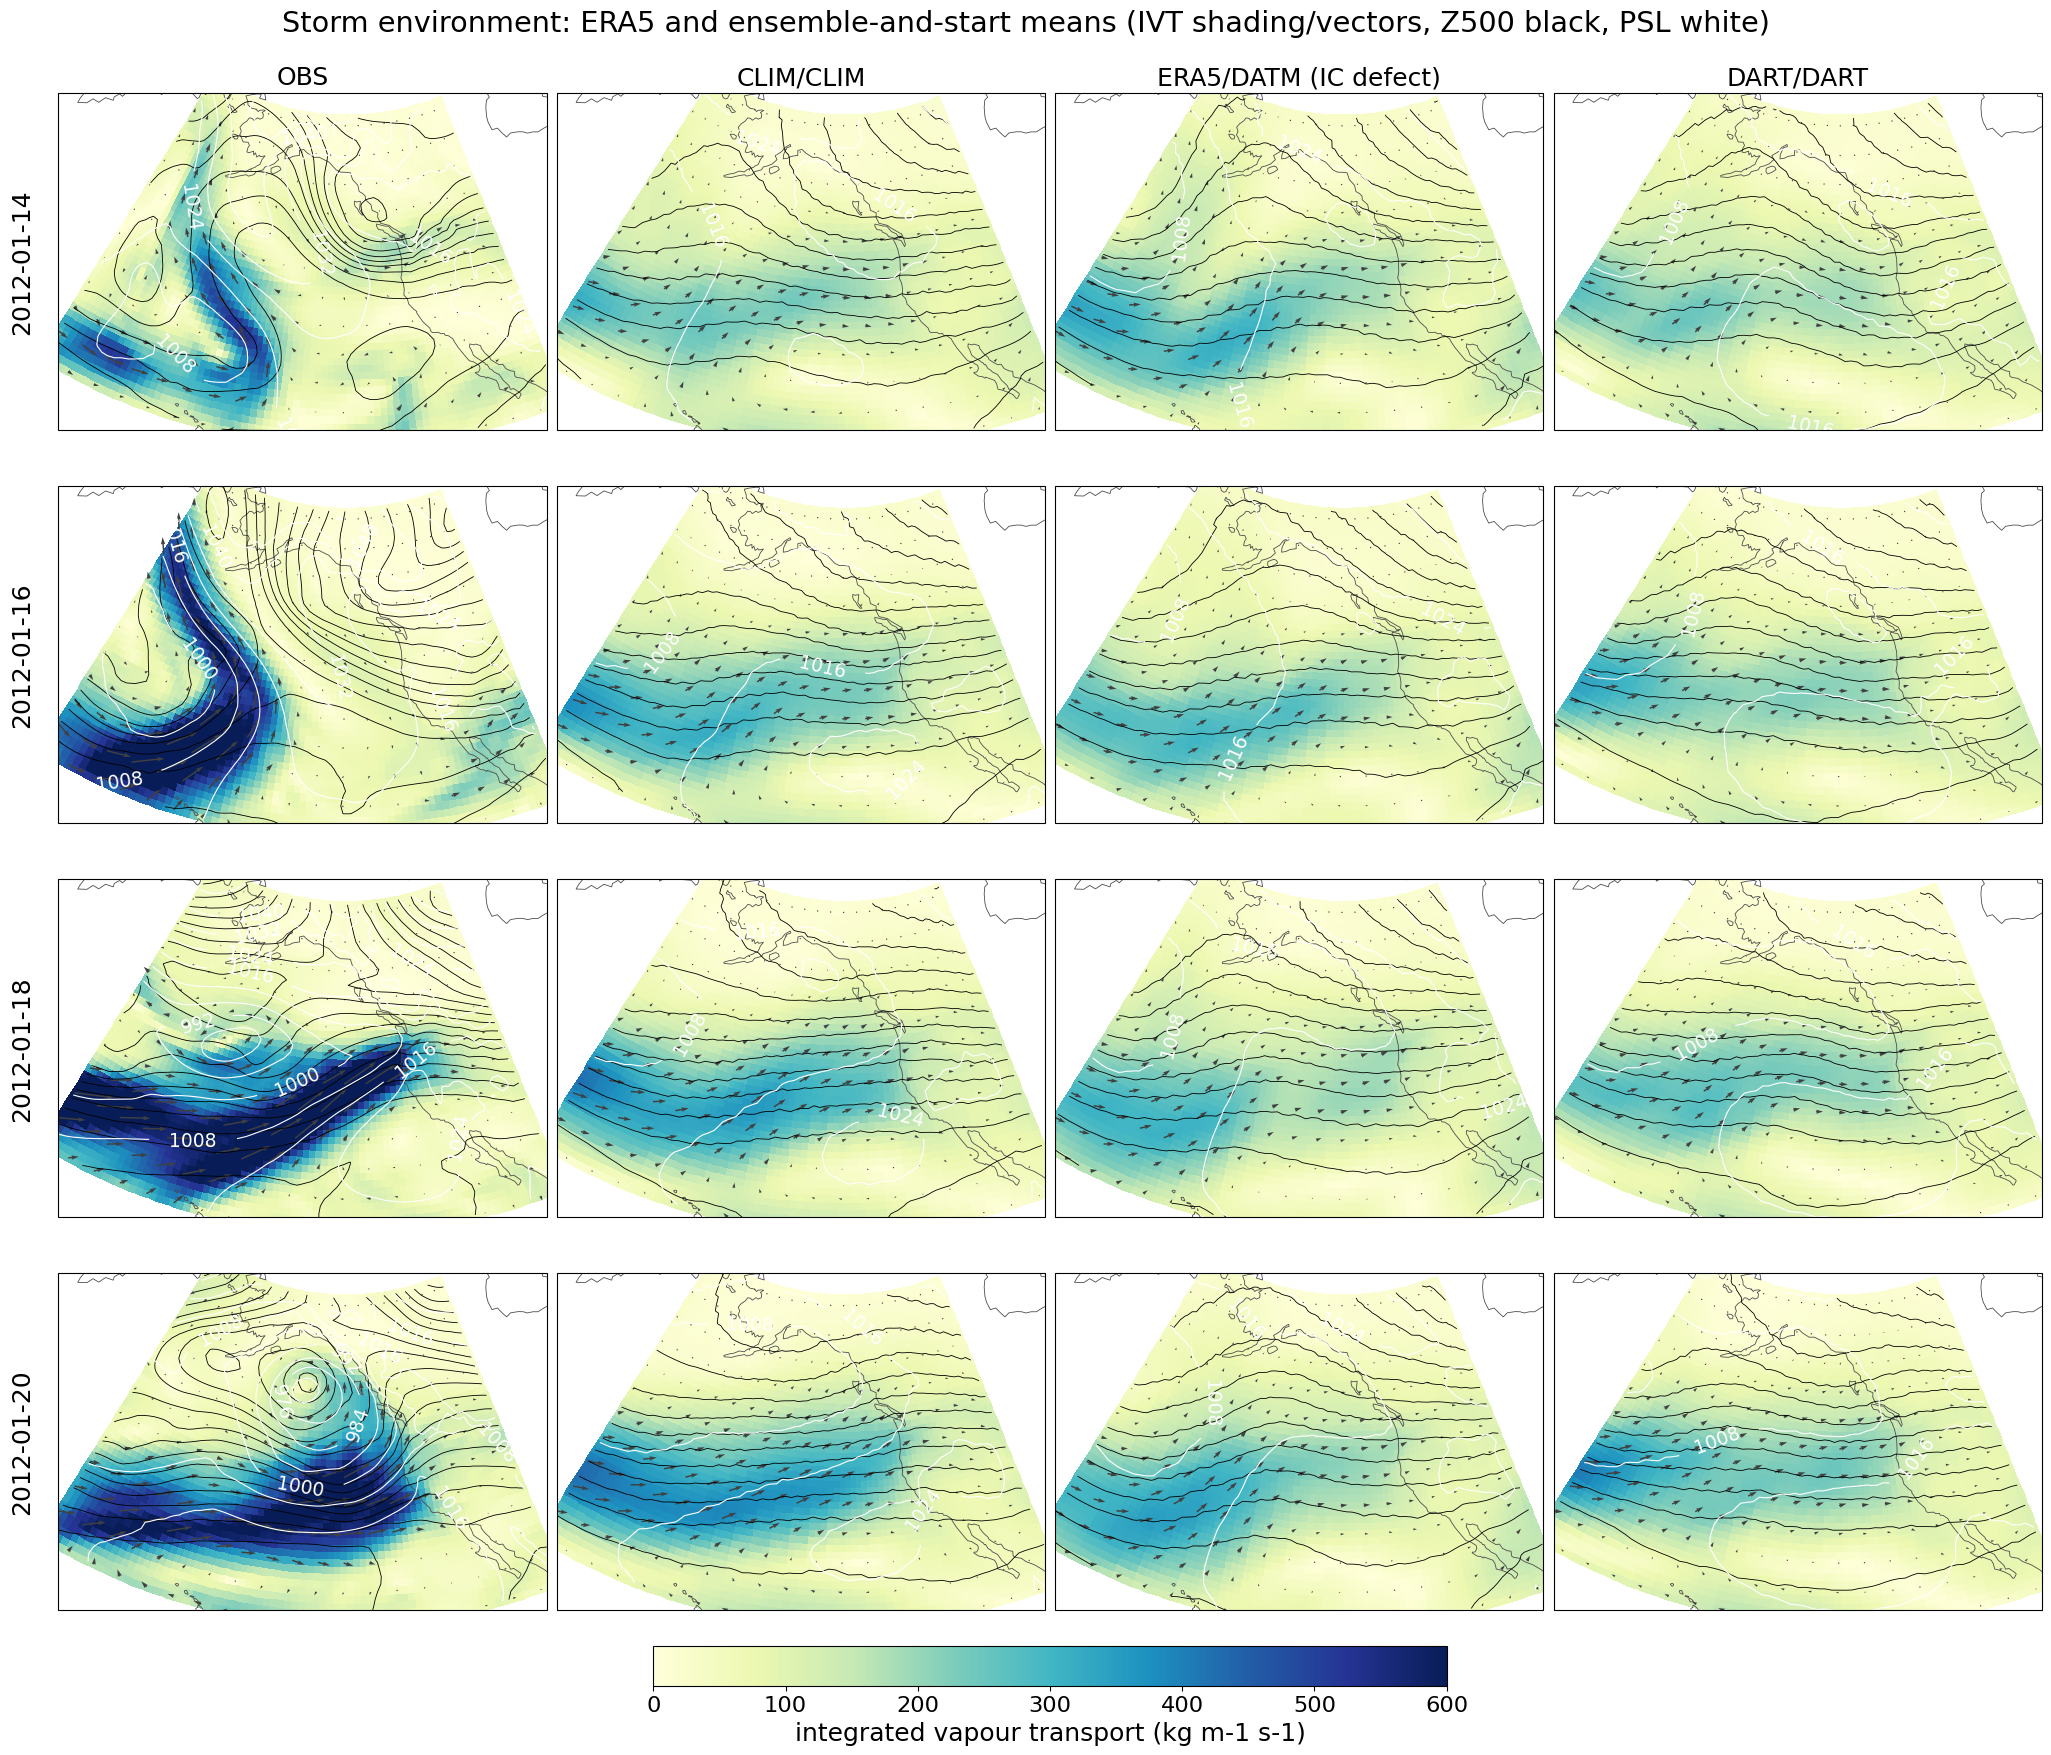

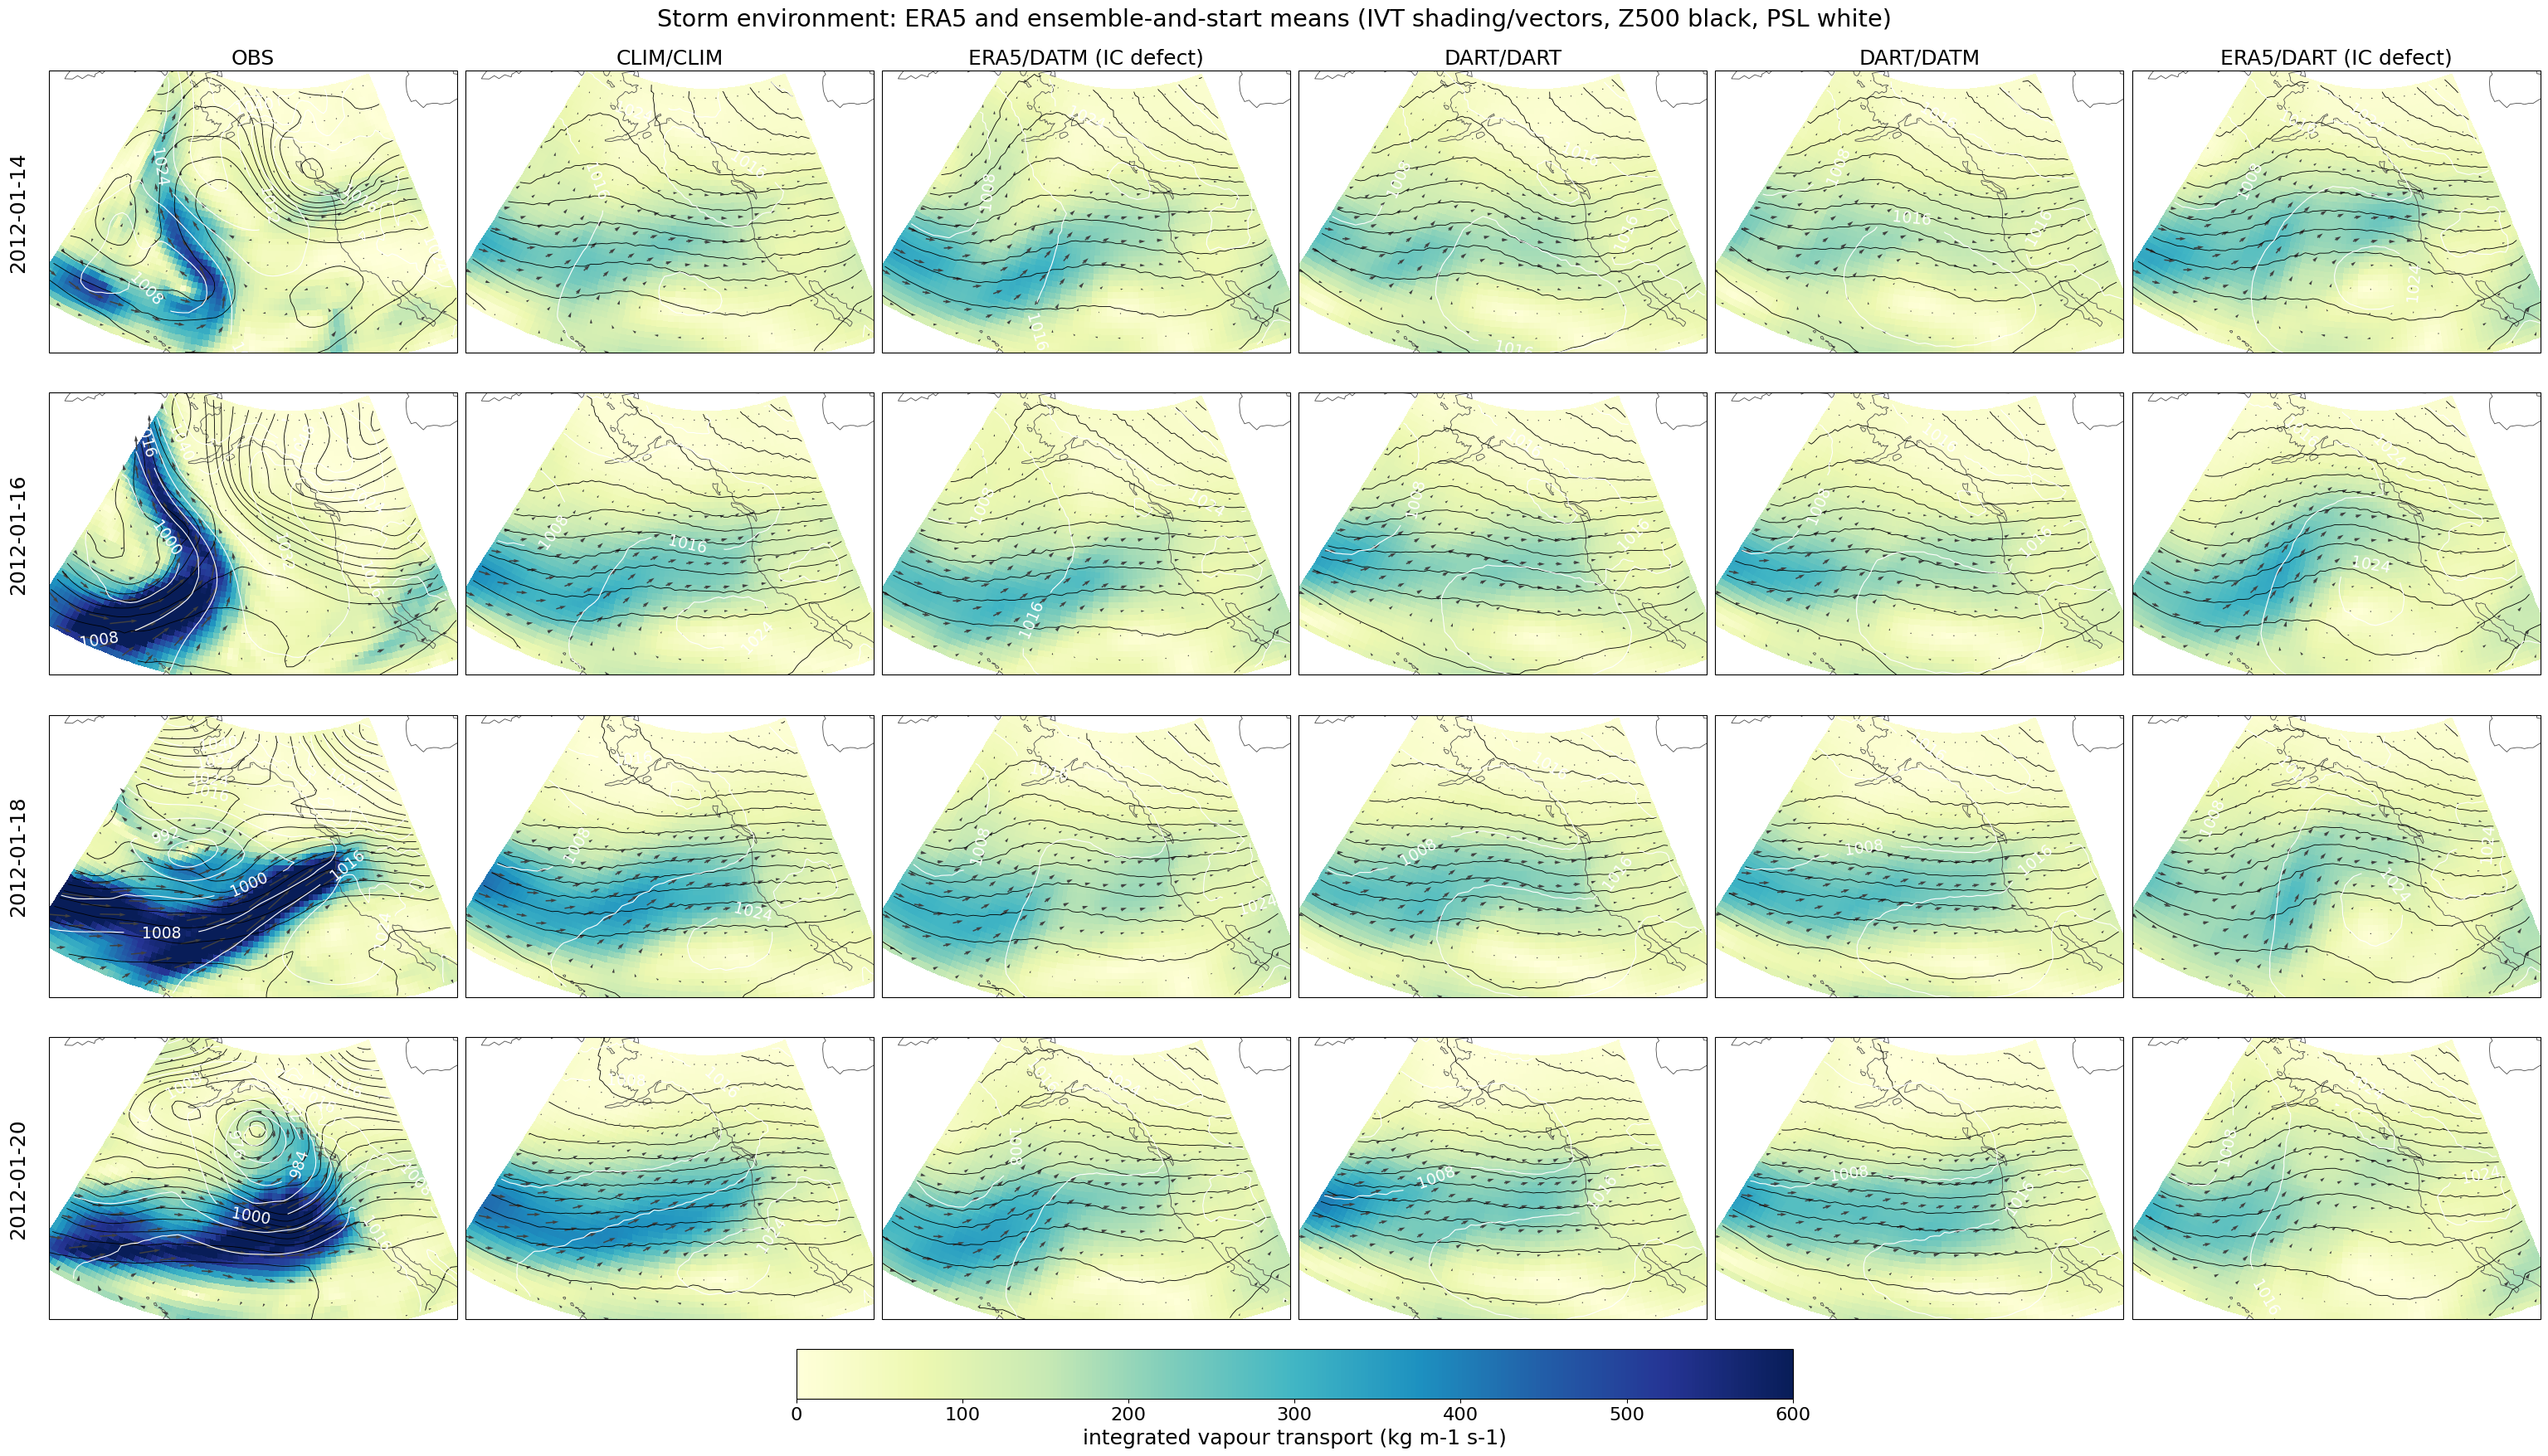

In [6]:
# ============================ Figure settings: edit here and rerun this cell ============================
SHOW = True          # False: save the figures without showing them
FIGURE_DPI = 200
FONT_SIZE = 18       # base font size (pt); every label of every figure scales with it
FONT_SCALES = dict(label=1.0, title=1.0, tick=0.9, legend=1.0, suptitle=1.15, cell=0.75)  # x FONT_SIZE

from util.fcst_init_plotting import set_font_size
set_font_size(FONT_SIZE, **FONT_SCALES)
save = figure_saver(case.figure_dir, dpi=FIGURE_DPI, show=SHOW)
# =========================================================================================================

from util.winter_storm_case import plot_environment

days = list(pd.to_datetime(list(cfg.env_days)))
by_day = lambda src: {d: env.sel(source=src, time=d, drop=True) for d in days}
obs_days = by_day("OBS")
for tag, cfgs in (("primary", list(cfg.primary)), ("all", list(cfg.configs))):
    save(plot_environment(days, obs_days, {c: by_day(c) for c in cfgs}, list(cfg.ic_defect), extent=cfg.env_extent,
                          title="Storm environment: ERA5 and ensemble-and-start means (IVT shading/vectors, Z500 black, "
                                "PSL white)"),
         f"storm_environment_{tag}.png")